In [557]:
import pandas as pd
import yfinance as yf
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf


In [558]:
doviz_semboller = ["THYAO.IS","PGSUS.IS","FROTO.IS","ARCLK.IS","SISE.IS","TUPRS.IS","AKSA.IS"]
ic_pazar_semboller= ["BIMAS.IS","MGROS.IS","TCELL.IS","TTKOM.IS","AKBNK.IS","GARAN.IS","ISCTR.IS"]

In [559]:
df = yf.download(doviz_semboller + ic_pazar_semboller + ["USDTRY=X"],start="2016-01-01",multi_level_index=False)

[*********************100%***********************]  15 of 15 completed


In [560]:
df.to_parquet("raw_data.parquet")

In [561]:
aylik = df["Close"].resample('ME').last()
ret   = np.log(aylik / aylik.shift(1)).dropna()

In [562]:
def name(name):
    name = name[:-3]
    return name
ret = ret.rename(columns=name)
ret = ret.rename(columns={"USDTR":"USDTRY"})

In [563]:
ret
df.columns

MultiIndex([( 'Close', 'AKBNK.IS'),
            ( 'Close',  'AKSA.IS'),
            ( 'Close', 'ARCLK.IS'),
            ( 'Close', 'BIMAS.IS'),
            ( 'Close', 'FROTO.IS'),
            ( 'Close', 'GARAN.IS'),
            ( 'Close', 'ISCTR.IS'),
            ( 'Close', 'MGROS.IS'),
            ( 'Close', 'PGSUS.IS'),
            ( 'Close',  'SISE.IS'),
            ( 'Close', 'TCELL.IS'),
            ( 'Close', 'THYAO.IS'),
            ( 'Close', 'TTKOM.IS'),
            ( 'Close', 'TUPRS.IS'),
            ( 'Close', 'USDTRY=X'),
            (  'High', 'AKBNK.IS'),
            (  'High',  'AKSA.IS'),
            (  'High', 'ARCLK.IS'),
            (  'High', 'BIMAS.IS'),
            (  'High', 'FROTO.IS'),
            (  'High', 'GARAN.IS'),
            (  'High', 'ISCTR.IS'),
            (  'High', 'MGROS.IS'),
            (  'High', 'PGSUS.IS'),
            (  'High',  'SISE.IS'),
            (  'High', 'TCELL.IS'),
            (  'High', 'THYAO.IS'),
            (  'High', 'TTKO

In [564]:
usd_aylik = aylik["USDTRY=X"]
ret_usd = np.log(aylik.div(usd_aylik, axis=0) / aylik.div(usd_aylik, axis=0).shift(1))

In [596]:
ret_usd = ret_usd.dropna()
(ret_usd - ret).add(ret["USDTRY"], axis=0).abs().max()

Ticker
AKBNK     2.914335e-16
AKSA      2.324529e-16
ARCLK     2.844947e-16
BIMAS     3.521489e-16
FROTO     3.022756e-16
GARAN     2.949030e-16
ISCTR     2.289835e-16
MGROS     2.983724e-16
PGSUS     2.324529e-16
SISE      3.157197e-16
TCELL     2.896988e-16
THYAO     2.862294e-16
TTKOM     3.018419e-16
TUPRS     3.313322e-16
USDTR              NaN
USDTRY             NaN
dtype: float64

In [566]:
ret_usd = ret_usd.rename(columns=name)
ret_usd.rename(columns={"USDTR":"USDTRY"})
x = ret_usd - ret
x

Ticker,AKBNK,AKSA,ARCLK,BIMAS,FROTO,GARAN,ISCTR,MGROS,PGSUS,SISE,TCELL,THYAO,TTKOM,TUPRS,USDTR,USDTRY
Date,,,,,,,,,,,,,,,,
2016-02-29,-0.006191,-0.006191,-0.006191,-0.006191,-0.006191,-0.006191,-0.006191,-0.006191,-0.006191,-0.006191,-0.006191,-0.006191,-0.006191,-0.006191,NaN,NaN
2016-03-31,0.053248,0.053248,0.053248,0.053248,0.053248,0.053248,0.053248,0.053248,0.053248,0.053248,0.053248,0.053248,0.053248,0.053248,NaN,NaN
2016-04-30,0.007760,0.007760,0.007760,0.007760,0.007760,0.007760,0.007760,0.007760,0.007760,0.007760,0.007760,0.007760,0.007760,0.007760,NaN,NaN
2016-05-31,-0.049334,-0.049334,-0.049334,-0.049334,-0.049334,-0.049334,-0.049334,-0.049334,-0.049334,-0.049334,-0.049334,-0.049334,-0.049334,-0.049334,NaN,NaN
2016-06-30,0.022397,0.022397,0.022397,0.022397,0.022397,0.022397,0.022397,0.022397,0.022397,0.022397,0.022397,0.022397,0.022397,0.022397,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-07-31,-0.018286,-0.018286,-0.018286,-0.018286,-0.018286,-0.018286,-0.018286,-0.018286,-0.018286,-0.018286,-0.018286,-0.018286,-0.018286,-0.018286,NaN,NaN
2026-08-31,-0.015572,-0.015572,-0.015572,-0.015572,-0.015572,-0.015572,-0.015572,-0.015572,-0.015572,-0.015572,-0.015572,-0.015572,-0.015572,-0.015572,NaN,NaN
2026-09-30,-0.015655,-0.015655,-0.015655,-0.015655,-0.015655,-0.015655,-0.015655,-0.015655,-0.015655,-0.015655,-0.015655,-0.015655,-0.015655,-0.015655,NaN,NaN


In [567]:
ret.count(
)

Ticker
AKBNK     130
AKSA      130
ARCLK     130
BIMAS     130
FROTO     130
GARAN     130
ISCTR     130
MGROS     130
PGSUS     130
SISE      130
TCELL     130
THYAO     130
TTKOM     130
TUPRS     130
USDTRY    130
dtype: int64

In [568]:
ret.abs().max()

Ticker
AKBNK     0.324377
AKSA      0.288388
ARCLK     0.300066
BIMAS     0.237006
FROTO     0.389951
GARAN     0.459967
ISCTR     0.416894
MGROS     0.373525
PGSUS     0.481451
SISE      0.371006
TCELL     0.353640
THYAO     0.371837
TTKOM     0.345799
TUPRS     0.310864
USDTRY    0.321469
dtype: float64

In [569]:
dolar = ["USDTRY.IS"]
gruplar = {s: "doviz" for s in doviz_semboller}
gruplar.update({s: "ic pazar" for s in ic_pazar_semboller})
gruplar.update({s: "dolar" for s in dolar})
sonuclar = []

for i in ret.columns:
    lm_ols = smf.ols(f'{i} ~ USDTRY',data = ret).fit()
    lm_hac = smf.ols(f'{i} ~ USDTRY',data = ret).fit(
        cov_type="HAC",cov_kwds={"maxlags": 4}
    )
    sonuclar.append({
        "ticker": i,
        "group": gruplar[i+".IS"],
        "beta": lm_ols.params["USDTRY"],
        "p_ols": lm_ols.pvalues["USDTRY"],
        "p_hac": lm_hac.pvalues["USDTRY"],
        "alpha": lm_ols.params["Intercept"],
        "r2": lm_ols.rsquared,
        "n": int(lm_ols.nobs),

    })
sonuc = pd.DataFrame(sonuclar)
sonuc["beta usd"] = sonuc["beta"] - 1
sonuc = sonuc.sort_values("beta",ascending=False)

In [570]:
sonuc = sonuc[sonuc["group"] != "dolar"]

In [571]:
sonuc.set_index(["ticker"])

,group,beta,p_ols,p_hac,alpha,r2,n,beta usd
ticker,,,,,,,,
FROTO,doviz,0.555040,0.001122,0.000330,0.016984,0.079876,130,-0.444960
SISE,doviz,0.474063,0.004155,0.013751,0.011746,0.062398,130,-0.525937
ARCLK,doviz,0.248315,0.152749,0.281202,0.007846,0.015908,130,-0.751685
THYAO,doviz,0.074125,0.722353,0.750052,0.027122,0.000990,130,-0.925875
TUPRS,doviz,0.068709,0.712618,0.625061,0.031602,0.001064,130,-0.931291
AKSA,doviz,0.041845,0.821887,0.834411,0.028108,0.000397,130,-0.958155
BIMAS,ic pazar,0.024560,0.853871,0.838828,0.028049,0.000266,130,-0.975440
TCELL,ic pazar,-0.213056,0.173498,0.379086,0.024579,0.014424,130,-1.213056
PGSUS,doviz,-0.267838,0.278571,0.378026,0.034504,0.009166,130,-1.267838


In [572]:
sonuc.groupby("group")["beta"].agg(["mean", "median","std","count"])


,mean,median,std,count
group,,,,
doviz,0.170608,0.074125,0.281193,7
ic pazar,-0.322510,-0.342695,0.189645,7


In [573]:
from scipy import stats

d = sonuc.loc[sonuc.group == "doviz", "beta"]
i = sonuc.loc[sonuc.group == "ic pazar", "beta"]
stats.ttest_ind(d,i,equal_var=False)

TtestResult(statistic=np.float64(3.8466794573041323), pvalue=np.float64(0.0029423602985191957), df=np.float64(10.522576601413778))

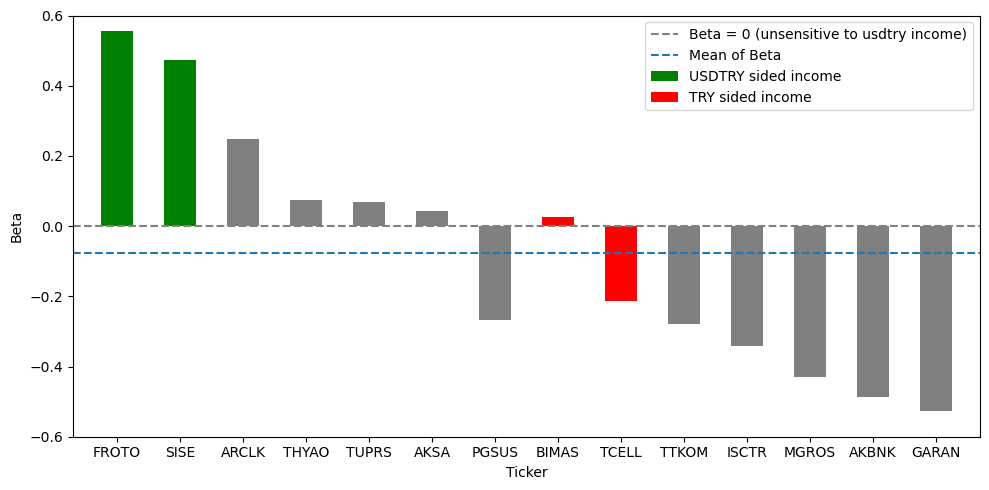

In [601]:
r2_plot = sonuc["beta"].mean()
doviz = sonuc[sonuc["group"] == "doviz"]
ic_pazar = sonuc[sonuc["group"] == "ic pazar"]
significant = sonuc[sonuc["p_hac"] <= 0.05]

g = sonuc.sort_values("beta", ascending=False)
renkler = np.where(g["p_hac"] >= 0.05, "gray", "green")
renkler2 = np.where(g["p_hac"] >= 0.05, "gray", "red")  # p > 0.05 gri, diğerleri yeşil

plt.figure(figsize=(10,5))
plt.bar(doviz["ticker"],doviz["beta"].sort_values(ascending=False), width=0.5,color=renkler,label="USDTRY sided income")
plt.bar(ic_pazar["ticker"],ic_pazar["beta"].sort_values(ascending=False),width=0.5,color=renkler2,label="TRY sided income")
plt.axhline(0,color="gray",linestyle="--", label="Beta = 0 (unsensitive to usdtry income)")
plt.axhline(r2_plot,label="Mean of Beta", linestyle="--")
plt.xlabel("Ticker")
plt.ylabel("Beta")
plt.axis([-0.7,13.7,-0.6,0.6])
plt.legend()
plt.tight_layout()

In [575]:
def rolling_beta(y,x,window=36):
    return y.rolling(window).cov(x) / x.rolling(window).var()

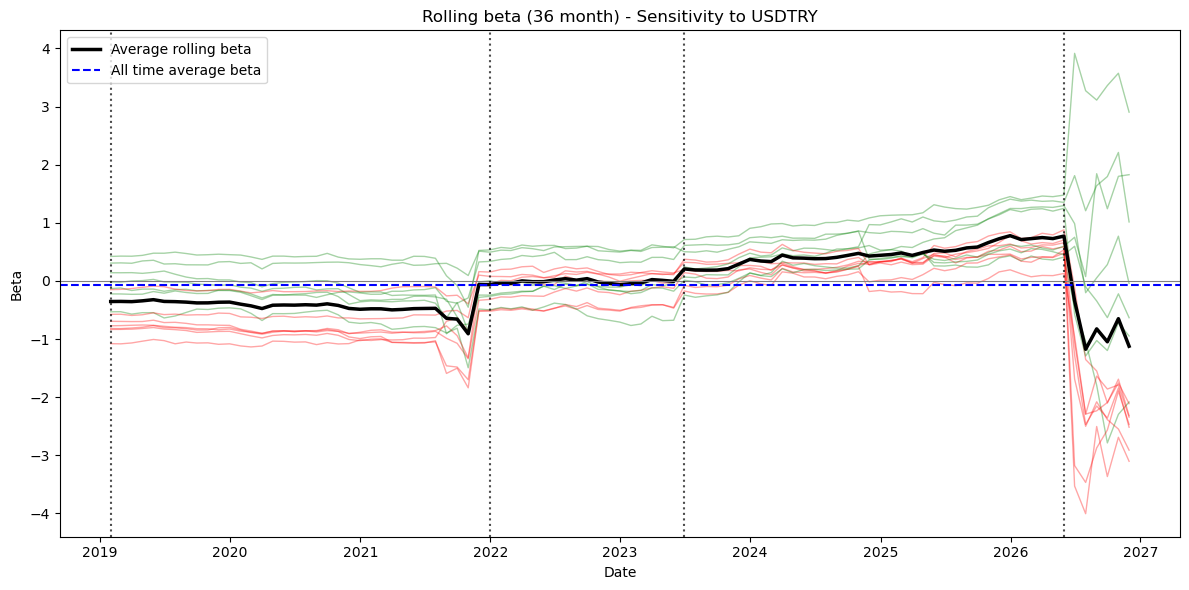

In [598]:
usd = ret["USDTRY"]
stocks = [c for c in ret.columns if c != "USDTRY"]

rb = pd.DataFrame({h: rolling_beta(ret[h], usd) for h in stocks}).dropna(how="all")

group_map = dict(zip(sonuc["ticker"], sonuc["group"]))
colors = {"doviz": "green", "ic pazar": "red"}


plt.figure(figsize=(12,6))

for h in stocks:
    g = group_map.get(h)
    color = colors.get(g, "gray")
    plt.plot(rb.index,rb[h],alpha = 0.35, linewidth= 1,color=color )

plt.plot(rb.index, rb.mean(axis=1),color="black",linewidth=2.5,label="Average rolling beta")
plt.axhline(sonuc["beta"].mean(),color="blue",linestyle="--",label="All time average beta")
plt.axhline(0,color="gray",linewidth=0.8)

for date in ["2019-01-31","2021-12-31","2023-06-30","2026-05-31"]:
    plt.axvline(pd.Timestamp(date),color="black",linestyle=":",alpha=0.7)

plt.title("Rolling beta (36 month) - Sensitivity to USDTRY")
plt.xlabel("Date")
plt.ylabel("Beta")
plt.legend()
plt.tight_layout()
plt.show()

In [577]:
yeni_sonuclar = {s["ticker"]: s for s in sonuclar if s["ticker"] not in ("FROTO", "SISE","USDTRY")}
wo = pd.DataFrame(yeni_sonuclar)

In [578]:
wo = wo.T
wo.set_index(["ticker"])


,group,beta,p_ols,p_hac,alpha,r2,n
ticker,,,,,,,
AKBNK,ic pazar,-0.487888,0.014136,0.090744,0.031748,0.046125,130
AKSA,doviz,0.041845,0.821887,0.834411,0.028108,0.000397,130
ARCLK,doviz,0.248315,0.152749,0.281202,0.007846,0.015908,130
BIMAS,ic pazar,0.02456,0.853871,0.838828,0.028049,0.000266,130
GARAN,ic pazar,-0.52734,0.007296,0.058026,0.036793,0.054895,130
ISCTR,ic pazar,-0.342695,0.0852,0.205914,0.031393,0.022969,130
MGROS,ic pazar,-0.431256,0.02213,0.209711,0.035866,0.04023,130
PGSUS,doviz,-0.267838,0.278571,0.378026,0.034504,0.009166,130
TCELL,ic pazar,-0.213056,0.173498,0.379086,0.024579,0.014424,130


In [590]:
y = pd.DataFrame(wo.groupby("group")["beta"].agg("mean"))
x = pd.DataFrame(sonuc.groupby("group")["beta"].agg("mean"))
y , x

(              beta
 group             
 doviz     0.033031
 ic pazar  -0.32251,
               beta
 group             
 doviz     0.170608
 ic pazar -0.322510)